# Data Science Tool Mastery Project
## Diamond Price Analysis & Prediction – 53,940 records
**Task 4 – Yuva Intern | AI/ML Research Specialist Internship**

**Objectives**
1. Master the industry-standard tools of the data-science stack: **NumPy, Pandas, SQL (SQLite), Matplotlib, Seaborn, SciPy, Statsmodels, Scikit-learn, Jupyter**.
2. Demonstrate proficiency through practical exercises, each backed by measured numbers.
3. Produce a portfolio-quality, reproducible project.

**Dataset:** the *diamonds* dataset – 53,940 diamonds with price (USD), carat, cut, colour, clarity and physical dimensions (public dataset from the seaborn-data repository, originally from ggplot2). It is large enough to need vectorised code, makes performance differences visible, and supports complex operations (SQL window functions, hypothesis tests, ML pipelines).

| Tool | Where it is demonstrated |
|---|---|
| NumPy | §3 – vectorisation benchmark, broadcasting, masks, least-squares from scratch |
| Pandas | §4 – cleaning, groupby, pivot, merge, transform, qcut, method chaining |
| SQL (sqlite3) | §5 – aggregation, HAVING, CTE, window functions |
| SciPy / Statsmodels | §6 – distributions, CIs, bootstrap, t-test, ANOVA, chi-square, OLS |
| Matplotlib / Seaborn | §7 – visualisations |
| Scikit-learn | §8 – pipelines, cross-validation, tuning, 5 models, permutation importance |

In [1]:
import os, json, time, sqlite3, warnings, platform, sys
import numpy as np, pandas as pd, matplotlib, seaborn as sns, scipy, sklearn, statsmodels
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("images", exist_ok=True)
SEED = 42; rng = np.random.default_rng(SEED)
M = {}                                   # every key number is stored here and exported to metrics.json
f = lambda v: float(np.round(v, 4))

def save(name):
    plt.tight_layout(); plt.savefig(f"images/{name}.png", dpi=130); plt.show()

print("Python", sys.version.split()[0], "|", platform.system())
for n, l in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib), ("seaborn", sns), ("scipy", scipy), ("statsmodels", statsmodels), ("scikit-learn", sklearn)]:
    print(f"{n:<13}{l.__version__}")
print("sqlite", sqlite3.sqlite_version)

Python 3.12.3 | Linux
numpy        2.4.4
pandas       3.0.2
matplotlib   3.10.8
seaborn      0.13.2
scipy        1.17.1
statsmodels  0.15.0
scikit-learn 1.8.0
sqlite 3.45.1


## 1. Load the Data

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
try: raw = pd.read_csv("data/diamonds_raw.csv")
except FileNotFoundError:
    raw = pd.read_csv(URL); raw.to_csv("data/diamonds_raw.csv", index=False)
raw = raw.rename(columns={"depth": "depth_pct", "table": "table_pct"})   # 'table' is a reserved SQL word
M["rows_raw"] = len(raw); M["cols"] = raw.shape[1]
print(raw.shape, f"| memory: {raw.memory_usage(deep=True).sum()/1e6:.1f} MB")
raw.head()

(53940, 10) | memory: 11.5 MB


,carat,cut,color,clarity,depth_pct,table_pct,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


**Data dictionary** – `carat` weight (0.2–5.01) · `cut` Fair<Good<Very Good<Premium<Ideal · `color` J (worst) → D (best) · `clarity` I1 (worst) → IF (best) · `depth_pct` total depth % = 2z/(x+y) · `table_pct` width of top facet relative to widest point · `price` USD (326–18,823) · `x, y, z` length, width, depth in mm.

## 2. Data Quality Audit

In [3]:
print("Missing values:", int(raw.isna().sum().sum()))
dups = int(raw.duplicated().sum()); print("Exact duplicate rows:", dups)
zero = raw[(raw[["x", "y", "z"]] == 0).any(axis=1)]; print("Rows with a zero dimension (physically impossible):", len(zero))
big = raw[(raw.y > 20) | (raw.z > 10)]; print("Rows with impossible size (y>20mm or z>10mm):", len(big)); print(big[["carat", "price", "x", "y", "z"]])
calc_depth = 2 * raw.z / (raw.x + raw.y) * 100
bad_depth = ((calc_depth - raw.depth_pct).abs() > 1) & (raw.z > 0)
print("Rows where listed depth% disagrees with x,y,z by >1 point:", int(bad_depth.sum()))
M.update(dups=dups, zero_dim=len(zero), impossible=len(big), bad_depth=int(bad_depth.sum()))

Missing values: 0
Exact duplicate rows: 146
Rows with a zero dimension (physically impossible): 20
Rows with impossible size (y>20mm or z>10mm): 3
       carat  price     x      y      z
24067   2.00  12210  8.09  58.90   8.06
48410   0.51   1970  5.12   5.15  31.80
49189   0.51   2075  5.15  31.80   5.12
Rows where listed depth% disagrees with x,y,z by >1 point: 80


## 3. NumPy Mastery

### 3.1 Vectorisation vs Python loops (53,940 elements)

In [4]:
carat = raw["carat"].to_numpy(); price = raw["price"].to_numpy(dtype=float)

t0 = time.perf_counter(); ppc_loop = [price[i] / carat[i] for i in range(len(price))]; t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); ppc_vec = price / carat;                                       t_vec = time.perf_counter() - t0
print(f"Python loop : {t_loop*1000:8.2f} ms")
print(f"NumPy vector: {t_vec*1000:8.2f} ms   -> {t_loop/t_vec:,.0f}x faster")
print("Same result :", np.allclose(ppc_loop, ppc_vec))
M.update(t_loop_ms=f(t_loop*1000), t_vec_ms=f(t_vec*1000), speedup=f(t_loop/t_vec))

Python loop :    14.30 ms
NumPy vector:     0.34 ms   -> 42x faster
Same result : True


### 3.2 Broadcasting – standardise every numeric column in one line

In [5]:
num_cols = ["carat", "depth_pct", "table_pct", "price", "x", "y", "z"]
A = raw[num_cols].to_numpy(dtype=float)                  # shape (53940, 7)
Z = (A - A.mean(axis=0)) / A.std(axis=0)                 # (53940,7) - (7,) broadcast along rows
print("shape:", A.shape, "| column means after scaling:", Z.mean(axis=0).round(10), "| std:", Z.std(axis=0).round(3))

shape: (53940, 7) | column means after scaling: [ 0.  0.  0. -0.  0. -0.  0.] | std: [1. 1. 1. 1. 1. 1. 1.]


### 3.3 Boolean masks, `np.where`, percentiles

In [6]:
mask = (carat >= 1) & (price < 5000)
print(f"Diamonds >= 1 carat but under $5,000: {mask.sum():,} ({mask.mean():.1%})")
tier = np.where(price < 1000, "budget", np.where(price < 5000, "mid", "premium"))
print(dict(zip(*np.unique(tier, return_counts=True))))
print("Price percentiles 10/25/50/75/90/99:", np.percentile(price, [10, 25, 50, 75, 90, 99]).round(0))

Diamonds >= 1 carat but under $5,000: 4,582 (8.5%)
{np.str_('budget'): np.int64(14499), np.str_('mid'): np.int64(24714), np.str_('premium'): np.int64(14727)}
Price percentiles 10/25/50/75/90/99: [  646.   950.  2401.  5324.  9821. 17378.]


### 3.4 Linear algebra – regression from scratch with `np.linalg.lstsq`

A log-log model `log(price) = b0 + b1*log(carat)` estimates the **price elasticity of carat**: a 1% bigger diamond costs about b1 % more. Solved here directly by least squares and checked against `np.polyfit`.

In [7]:
ok = (raw.carat > 0) & (raw.price > 0)
X = np.column_stack([np.ones(ok.sum()), np.log(raw.loc[ok, "carat"])]); y = np.log(raw.loc[ok, "price"])
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
b1_check, b0_check = np.polyfit(np.log(raw.loc[ok, "carat"]), y, 1)
resid = y - X @ beta; r2 = 1 - resid.var() / y.var()
print(f"lstsq   : intercept = {beta[0]:.4f}, elasticity = {beta[1]:.4f}")
print(f"polyfit : intercept = {b0_check:.4f}, elasticity = {b1_check:.4f}   (identical)")
print(f"R-squared = {r2:.4f}")
M.update(elasticity=f(beta[1]), loglog_r2=f(r2))

lstsq   : intercept = 8.4487, elasticity = 1.6758
polyfit : intercept = 8.4487, elasticity = 1.6758   (identical)
R-squared = 0.9330


## 4. Pandas Mastery – Cleaning & Transformation

In [8]:
df = (raw
      .drop_duplicates()
      .query("x > 0 and y > 0 and z > 0 and y < 20 and z < 10")
      .reset_index(drop=True))
M["rows_clean"] = len(df); M["removed"] = len(raw) - len(df)
print(f"{len(raw):,} -> {len(df):,} rows ({len(raw)-len(df)} removed: {dups} duplicates + impossible dimensions)")

# ordered categorical types
df["cut"]     = pd.Categorical(df["cut"],     ["Fair", "Good", "Very Good", "Premium", "Ideal"], ordered=True)
df["color"]   = pd.Categorical(df["color"],   list("JIHGFED"), ordered=True)
df["clarity"] = pd.Categorical(df["clarity"], ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"], ordered=True)

# feature engineering
df["volume"] = df.x * df.y * df.z
df["price_per_carat"] = df.price / df.carat
df["log_price"] = np.log(df.price); df["log_carat"] = np.log(df.carat)
df["carat_band"] = pd.cut(df.carat, [0, .5, 1, 1.5, 2, 6], labels=["<0.5", "0.5-1", "1-1.5", "1.5-2", "2+"])
df["price_quartile"] = pd.qcut(df.price, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
df.to_csv("data/diamonds_clean.csv", index=False)
df.dtypes

53,940 -> 53,772 rows (168 removed: 146 duplicates + impossible dimensions)


carat               float64
cut                category
color              category
clarity            category
depth_pct           float64
table_pct           float64
price                 int64
x                   float64
y                   float64
z                   float64
volume              float64
price_per_carat     float64
log_price           float64
log_carat           float64
carat_band         category
price_quartile     category
dtype: object

### 4.1 Outlier review (IQR rule)

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)
for c in ["price", "carat", "depth_pct", "table_pct"]:
    o = iqr_outliers(df[c]); print(f"{c:<10} outliers: {o.sum():>5,} ({o.mean():.1%})")
    M[f"out_{c}"] = int(o.sum())
print("\nPrice outliers are large, high-clarity stones (genuine) -> kept; modelled on log scale instead.")

price      outliers: 3,519 (6.5%)
carat      outliers: 1,867 (3.5%)
depth_pct  outliers: 2,523 (4.7%)
table_pct  outliers:   603 (1.1%)

Price outliers are large, high-clarity stones (genuine) -> kept; modelled on log scale instead.


### 4.2 Group-by, pivot, cross-tab

In [10]:
by_cut = (df.groupby("cut", observed=True)
            .agg(n=("price", "size"), avg_price=("price", "mean"), median_price=("price", "median"),
                 avg_carat=("carat", "mean"), avg_ppc=("price_per_carat", "mean")).round(2))
print(by_cut)
M["by_cut"] = by_cut.reset_index().astype({"cut": str}).to_dict("records")

               n  avg_price  median_price  avg_carat  avg_ppc
cut                                                          
Fair        1597    4340.68        3282.0       1.04  3761.65
Good        4888    3916.28        3038.0       0.85  3859.09
Very Good  12067    3981.09        2647.0       0.81  4014.45
Premium    13736    4578.36        3177.5       0.89  4222.37
Ideal      21484    3462.21        1813.0       0.70  3922.37


In [11]:
pv = df.pivot_table(index="cut", columns="color", values="price", aggfunc="mean", observed=True).round(0)
print(pv)
ct = pd.crosstab(df.clarity, df.cut, normalize="index").round(3); print(ct.head(4))

color           J       I       H       G       F       E       D
cut                                                              
Fair       4976.0  4608.0  5091.0  4220.0  3835.0  3690.0  4291.0
Good       4588.0  5032.0  4247.0  4096.0  3499.0  3426.0  3408.0
Very Good  5110.0  5257.0  4524.0  3874.0  3778.0  3216.0  3473.0
Premium    6288.0  5928.0  5196.0  4500.0  4328.0  3542.0  3627.0
Ideal      4923.0  4452.0  3896.0  3726.0  3378.0  2601.0  2635.0
cut       Fair   Good  Very Good  Premium  Ideal
clarity                                         
I1       0.285  0.128      0.114    0.275  0.198
SI2      0.050  0.117      0.229    0.320  0.284
SI1      0.031  0.119      0.248    0.274  0.328
VS2      0.021  0.080      0.212    0.274  0.413


### 4.3 Merge with a lookup table, `transform`, `rank`

In [12]:
lookup = pd.DataFrame({"cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"],
                       "grade_tier": ["Standard", "Standard", "Fine", "Fine", "Excellent"],
                       "cut_score": [1, 2, 3, 4, 5]})
lookup["cut"] = pd.Categorical(lookup["cut"], df["cut"].cat.categories, ordered=True)
dm = df.merge(lookup, on="cut", how="left", validate="many_to_one")
print("rows before/after merge:", len(df), len(dm), "| unmatched:", int(dm.grade_tier.isna().sum()))
print(dm.groupby("grade_tier", observed=True)["price"].agg(["count", "mean"]).round(0))

# transform: how expensive is each stone relative to others of the same carat band?
df["ppc_z_in_band"] = df.groupby("carat_band", observed=True)["price_per_carat"].transform(lambda s: (s - s.mean()) / s.std())
df["ppc_rank_in_cut"] = df.groupby("cut", observed=True)["price_per_carat"].rank(ascending=False, method="dense")
print("\nMost over-priced stones relative to their carat band:")
df.nlargest(3, "ppc_z_in_band")[["carat", "cut", "color", "clarity", "price", "ppc_z_in_band"]].round(2)

rows before/after merge: 53772 53772 | unmatched: 0
            count    mean
grade_tier               
Excellent   21484  3462.0
Fine        25803  4299.0
Standard     6485  4021.0

Most over-priced stones relative to their carat band:


,carat,cut,color,clarity,price,ppc_z_in_band
26583,1.0,Ideal,D,IF,16469,11.53
26408,1.0,Very Good,D,IF,16073,11.17
26333,1.0,Good,D,IF,15928,11.04


In [13]:
# melt (wide -> long)
wide = df.groupby("cut", observed=True)[["price", "carat", "volume"]].mean().round(2).reset_index()
print(wide.melt(id_vars="cut", var_name="metric", value_name="mean").head(6))

         cut metric     mean
0       Fair  price  4340.68
1       Good  price  3916.28
2  Very Good  price  3981.09
3    Premium  price  4578.36
4      Ideal  price  3462.21
5       Fair  carat     1.04


## 5. SQL with SQLite – the same data, queried with SQL

In [14]:
con = sqlite3.connect(":memory:")
df.drop(columns=["price_quartile", "carat_band", "ppc_z_in_band", "ppc_rank_in_cut"]).astype({"cut": str, "color": str, "clarity": str}).to_sql("diamonds", con, index=False)
q = lambda sql: pd.read_sql(sql, con)

print("1) Aggregation"); r1 = q('''SELECT cut, COUNT(*) AS n, ROUND(AVG(price)) AS avg_price, ROUND(AVG(price/carat)) AS avg_ppc
                                  FROM diamonds GROUP BY cut ORDER BY avg_price DESC'''); print(r1)
print("\n2) GROUP BY + HAVING (segments with > 500 stones)"); r2 = q('''SELECT clarity, color, COUNT(*) AS n, ROUND(AVG(price)) AS avg_price
                                  FROM diamonds GROUP BY clarity, color HAVING n > 500 ORDER BY avg_price DESC LIMIT 5'''); print(r2)

1) Aggregation
         cut      n  avg_price  avg_ppc
0    Premium  13736     4578.0   4222.0
1       Fair   1597     4341.0   3762.0
2  Very Good  12067     3981.0   4014.0
3       Good   4888     3916.0   3859.0
4      Ideal  21484     3462.0   3922.0

2) GROUP BY + HAVING (segments with > 500 stones)


  clarity color     n  avg_price
0     SI2     I   904     6981.0
1     SI2     H  1549     6059.0
2     VS2     I  1166     5684.0
3     SI1     I  1420     5345.0
4     VS2     J   729     5295.0


In [15]:
print("3) CTE + window function: 2 most expensive stones in each cut")
r3 = q('''WITH ranked AS (
            SELECT cut, carat, color, clarity, price,
                   RANK() OVER (PARTITION BY cut ORDER BY price DESC) AS rk
            FROM diamonds)
          SELECT * FROM ranked WHERE rk <= 2 ORDER BY cut, rk'''); print(r3)

print("\n4) Share of stones by price bucket (window SUM)")
r4 = q('''WITH b AS (SELECT CAST(price/2000 AS INT)*2000 AS bucket, COUNT(*) AS n FROM diamonds GROUP BY 1)
          SELECT bucket, n, ROUND(100.0*n/SUM(n) OVER (), 1) AS pct,
                 ROUND(100.0*SUM(n) OVER (ORDER BY bucket)/SUM(n) OVER (), 1) AS cum_pct FROM b'''); print(r4)

chk = df.groupby("cut", observed=True)["price"].mean().round(0)
print("\nSQL average price matches Pandas:", all(abs(chk[c] - r1.set_index("cut").loc[c, "avg_price"]) <= 1 for c in chk.index))
M["sql_cum_under_4000"] = float(r4[r4.bucket == 2000].cum_pct.iloc[0])

3) CTE + window function: 2 most expensive stones in each cut
         cut  carat color clarity  price  rk
0       Fair   2.01     G     SI1  18574   1
1       Fair   2.02     H     VS2  18565   2
2       Good   2.07     I     VS2  18707   1
3       Good   2.67     F     SI2  18686   2
4      Ideal   1.51     G      IF  18806   1
5      Ideal   2.07     G     SI2  18804   2
6    Premium   2.29     I     VS2  18823   1
7    Premium   2.29     I     SI1  18797   2
8  Very Good   2.00     G     SI1  18818   1
9  Very Good   2.00     H     SI1  18803   2

4) Share of stones by price bucket (window SUM)
   bucket      n   pct  cum_pct
0       0  24122  44.9     44.9
1    2000  10332  19.2     64.1
2    4000   7806  14.5     78.6
3    6000   3938   7.3     85.9
4    8000   2379   4.4     90.3
5   10000   1752   3.3     93.6
6   12000   1299   2.4     96.0
7   14000   1011   1.9     97.9
8   16000    826   1.5     99.4
9   18000    307   0.6    100.0

SQL average price matches Pandas: True


## 6. Statistical Analysis in Depth

Each subsection states the **concept**, shows a **worked example on this data**, and gives the **interpretation**.

### 6.1 Descriptive statistics and shape
**Concept.** The *mean* is the arithmetic average; the *median* is the middle value and is resistant to extreme values. *Variance/standard deviation* measure spread, *IQR* (Q3−Q1) measures spread of the middle 50%, and the *coefficient of variation* (std/mean) compares spread across different units. *Skewness* > 0 means a long right tail; *kurtosis* describes tail heaviness.

**Example.** Prices of expensive stones pull the mean above the median, so the mean overstates a "typical" price.

In [16]:
p = df["price"]
desc = pd.Series({"mean": p.mean(), "median": p.median(), "mode (rounded to $100)": (p // 100 * 100).mode()[0], "std": p.std(), "variance": p.var(),
                  "IQR": p.quantile(.75) - p.quantile(.25), "CV": p.std() / p.mean(), "skewness": stats.skew(p), "excess kurtosis": stats.kurtosis(p),
                  "min": p.min(), "max": p.max()}).round(3)
print(desc)
M.update(p_mean=f(p.mean()), p_median=f(p.median()), p_std=f(p.std()), p_iqr=f(p.quantile(.75) - p.quantile(.25)), p_cv=f(p.std() / p.mean()),
         p_skew=f(stats.skew(p)), p_kurt=f(stats.kurtosis(p)), p_skew_log=f(stats.skew(df.log_price)))
print(f"\nMean is ${p.mean() - p.median():,.0f} above the median; skew of log(price) = {stats.skew(df.log_price):.2f} (much closer to symmetric).")

mean                      3.931137e+03
median                    2.401000e+03
mode (rounded to $100)    7.000000e+02
std                       3.985853e+03
variance                  1.588702e+07
IQR                       4.373000e+03
CV                        1.014000e+00
skewness                  1.618000e+00
excess kurtosis           2.179000e+00
min                       3.260000e+02
max                       1.882300e+04
dtype: float64

Mean is $1,530 above the median; skew of log(price) = 0.11 (much closer to symmetric).


### 6.2 Testing for normality
**Concept.** Many methods (t-tests, linear regression residuals) assume approximate normality. The **Shapiro-Wilk** test (null hypothesis: data are normal) and a **Q-Q plot** (points on the diagonal = normal) check this. With very large samples tests reject for tiny deviations, so the plot and skewness matter as much as the p-value.

price      : W = 0.8014, p = 1.86e-61
log(price) : W = 0.9641, p = 1.60e-33


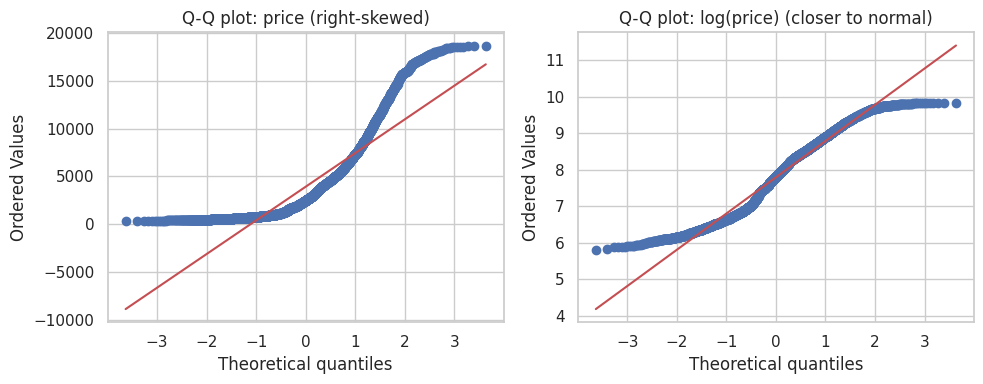

In [17]:
sample = df["price"].sample(5000, random_state=SEED); sample_log = df["log_price"].sample(5000, random_state=SEED)
w1, p1 = stats.shapiro(sample); w2, p2 = stats.shapiro(sample_log)
print(f"price      : W = {w1:.4f}, p = {p1:.2e}")
print(f"log(price) : W = {w2:.4f}, p = {p2:.2e}")
M.update(shapiro_raw=f(w1), shapiro_log=f(w2))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(sample, dist="norm", plot=ax[0]); ax[0].set_title("Q-Q plot: price (right-skewed)")
stats.probplot(sample_log, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot: log(price) (closer to normal)")
save("08_qq_plots")

### 6.3 Correlation: Pearson vs Spearman
**Concept.** *Pearson r* measures **linear** association; *Spearman ρ* measures **monotonic** association using ranks and is robust to outliers and curvature. When Spearman is much higher than Pearson the relationship is monotonic but non-linear. Correlation never proves causation.

In [18]:
rows = []
for c in ["carat", "x", "volume", "depth_pct", "table_pct"]:
    r, _ = stats.pearsonr(df[c], df.price); s, _ = stats.spearmanr(df[c], df.price); rows.append((c, r, s))
cor = pd.DataFrame(rows, columns=["feature", "pearson_r", "spearman_rho"]).round(3); print(cor)
r_ll, _ = stats.pearsonr(df.log_carat, df.log_price); print(f"\nlog(carat) vs log(price): r = {r_ll:.4f}  (curvature removed -> near-perfect linear)")
M["corr"] = cor.to_dict("records"); M["r_loglog"] = f(r_ll)

     feature  pearson_r  spearman_rho
0      carat      0.922         0.963
1          x      0.887         0.964
2     volume      0.923         0.964
3  depth_pct     -0.011         0.010
4  table_pct      0.127         0.171

log(carat) vs log(price): r = 0.9659  (curvature removed -> near-perfect linear)


### 6.4 Confidence intervals and the bootstrap
**Concept.** A 95% **confidence interval** gives a range that, over repeated sampling, would contain the true mean 95% of the time. The **bootstrap** estimates uncertainty for *any* statistic (here the median) by resampling the data with replacement.

In [19]:
n = len(p); mean, sem = p.mean(), stats.sem(p)
lo, hi = stats.t.interval(0.95, df=n - 1, loc=mean, scale=sem)
print(f"Mean price = ${mean:,.2f}, 95% CI = (${lo:,.2f}, ${hi:,.2f}), margin = ${(hi-lo)/2:,.2f}")

boot = np.array([np.median(rng.choice(p.to_numpy(), size=n, replace=True)) for _ in range(1000)])
blo, bhi = np.percentile(boot, [2.5, 97.5])
print(f"Median price = ${p.median():,.0f}, bootstrap 95% CI = (${blo:,.0f}, ${bhi:,.0f}) from 1,000 resamples")
M.update(ci_lo=f(lo), ci_hi=f(hi), boot_lo=f(blo), boot_hi=f(bhi))

Mean price = $3,931.14, 95% CI = ($3,897.45, $3,964.83), margin = $33.69


Median price = $2,401, bootstrap 95% CI = ($2,376, $2,441) from 1,000 resamples


### 6.5 Hypothesis testing and the confounding trap
**Concept.** A *hypothesis test* asks whether an observed difference could plausibly be chance. The **Welch t-test** compares two means without assuming equal variances. **Cohen's d** measures effect *size* (|d| ≈ 0.2 small, 0.5 medium, 0.8 large) because with 50,000 rows even trivial differences are "significant".

**Question:** Do Ideal-cut diamonds cost more than Fair-cut diamonds?

In [20]:
ideal = df[df.cut == "Ideal"]; fair = df[df.cut == "Fair"]
t, pv_ = stats.ttest_ind(ideal.price, fair.price, equal_var=False)
sp = np.sqrt((ideal.price.var() + fair.price.var()) / 2); d = (ideal.price.mean() - fair.price.mean()) / sp
print(f"Mean price  Ideal ${ideal.price.mean():,.0f}  vs  Fair ${fair.price.mean():,.0f}")
print(f"Welch t = {t:.2f}, p = {pv_:.2e}, Cohen's d = {d:.2f}")
print(f"Mean carat  Ideal {ideal.carat.mean():.2f}  vs  Fair {fair.carat.mean():.2f}   <-- the confounder")
M.update(ideal_mean=f(ideal.price.mean()), fair_mean=f(fair.price.mean()), t_cut=f(t), d_cut=f(d), ideal_carat=f(ideal.carat.mean()), fair_carat=f(fair.carat.mean()))

Mean price  Ideal $3,462  vs  Fair $4,341
Welch t = -9.51, p = 5.42e-21, Cohen's d = -0.24
Mean carat  Ideal 0.70  vs  Fair 1.04   <-- the confounder


**Paradox:** the "best" cut is *cheaper* on average – because Fair-cut stones are much heavier. Comparing like with like (same carat band) removes the confounder:

In [21]:
band = df[(df.carat >= 1.0) & (df.carat < 1.1)]
i2, f2 = band[band.cut == "Ideal"].price, band[band.cut == "Fair"].price
t2, p2_ = stats.ttest_ind(i2, f2, equal_var=False)
print(f"Within 1.0-1.1 carat  Ideal ${i2.mean():,.0f} (n={len(i2)})  vs  Fair ${f2.mean():,.0f} (n={len(f2)});  Welch t = {t2:.2f}, p = {p2_:.3f}")
M.update(band_ideal=f(i2.mean()), band_fair=f(f2.mean()), band_n_ideal=len(i2), band_n_fair=len(f2), band_p=f(p2_))

Within 1.0-1.1 carat  Ideal $6,121 (n=2053)  vs  Fair $4,240 (n=372);  Welch t = 23.40, p = 0.000


### 6.6 ANOVA, post-hoc test and effect size
**Concept.** **One-way ANOVA** tests whether ≥3 group means differ (F = between-group variance / within-group variance). **η² (eta-squared)** = SS_between / SS_total is the share of variance explained. **Kruskal-Wallis** is the rank-based alternative; **Tukey HSD** finds *which* pairs differ.

In [22]:
groups = [g.log_price.to_numpy() for _, g in df.groupby("cut", observed=True)]
F, pa = stats.f_oneway(*groups); H, pk = stats.kruskal(*groups)
grand = df.log_price.mean(); ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups); sst = ((df.log_price - grand) ** 2).sum()
print(f"ANOVA (log price ~ cut): F = {F:.1f}, p = {pa:.2e}, eta^2 = {ssb/sst:.4f}  -> cut alone explains only {ssb/sst:.1%} of price variance")
print(f"Kruskal-Wallis: H = {H:.1f}, p = {pk:.2e}")
tk = stats.tukey_hsd(*groups); iu = np.triu_indices(len(groups), 1); n_sig = int((tk.pvalue[iu] < 0.05).sum()); print(f"Tukey HSD: {n_sig} of 10 cut pairs differ significantly")
M.update(anova_F=f(F), eta2=f(ssb / sst), kw_H=f(H), tukey_sig=n_sig)

groups_c = [g.log_price.to_numpy() for _, g in df.groupby("carat_band", observed=True)]
gc = df.log_price.mean(); ssb_c = sum(len(g) * (g.mean() - gc) ** 2 for g in groups_c)
print(f"For comparison, carat band explains eta^2 = {ssb_c/sst:.1%}"); M["eta2_carat"] = f(ssb_c / sst)

ANOVA (log price ~ cut): F = 243.7, p = 8.40e-208, eta^2 = 0.0178  -> cut alone explains only 1.8% of price variance
Kruskal-Wallis: H = 958.1, p = 4.31e-206


Tukey HSD: 9 of 10 cut pairs differ significantly
For comparison, carat band explains eta^2 = 87.0%


### 6.7 Chi-square test of independence and Cramér's V
**Concept.** For two categorical variables, χ² compares observed counts with the counts expected if they were independent. **Cramér's V** (0–1) gives the strength.

In [23]:
tab = pd.crosstab(df.cut, df.clarity); chi2, pc, dof, _ = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"cut x clarity: chi2 = {chi2:,.0f}, dof = {dof}, p = {pc:.2e}, Cramer's V = {V:.3f}")
M.update(chi2=f(chi2), cramers_v=f(V))

cut x clarity: chi2 = 4,373, dof = 28, p = 0.00e+00, Cramer's V = 0.143


### 6.8 Probability and Bayes' rule
**Concept.** Conditional probability P(A|B) = P(A∩B)/P(B); Bayes' rule links P(A|B) and P(B|A).

In [24]:
A = df.price > 10000; B = df.carat > 1
pA, pB = A.mean(), B.mean(); pA_B = A[B].mean(); pB_A = B[A].mean()
print(f"P(price>$10k) = {pA:.4f} | P(carat>1) = {pB:.4f}")
print(f"P(price>$10k | carat>1) = {pA_B:.4f} | P(carat>1 | price>$10k) = {pB_A:.4f}")
print(f"Bayes check: P(B|A)*P(A)/P(B) = {pB_A*pA/pB:.4f}  (equals P(A|B))")
M.update(pA=f(pA), pB=f(pB), pA_B=f(pA_B), pB_A=f(pB_A))

P(price>$10k) = 0.0966 | P(carat>1) = 0.3243
P(price>$10k | carat>1) = 0.2969 | P(carat>1 | price>$10k) = 0.9967
Bayes check: P(B|A)*P(A)/P(B) = 0.2969  (equals P(A|B))


### 6.9 Multiple regression with Statsmodels (controlling for confounders)
`log(price) ~ log(carat) + cut + colour + clarity`. The coefficient on `log(carat)` is an elasticity; coefficients on dummy variables approximate % price differences relative to the base category (Fair cut, colour J, clarity I1).

In [25]:
import statsmodels.formula.api as smf
d2 = df.assign(cut=df.cut.astype(str), color=df.color.astype(str), clarity=df.clarity.astype(str))
ols = smf.ols("log_price ~ log_carat + C(cut, Treatment('Fair')) + C(color, Treatment('J')) + C(clarity, Treatment('I1'))", data=d2).fit()
print(f"R-squared = {ols.rsquared:.4f}, adj R-squared = {ols.rsquared_adj:.4f}, n = {int(ols.nobs):,}")
co = ols.params.to_frame("coef").assign(pvalue=ols.pvalues, premium_pct=(np.exp(ols.params) - 1) * 100).round(4)
print(co.loc[[i for i in co.index if i == "log_carat" or "cut" in i]])
M.update(ols_r2=f(ols.rsquared), ols_elast=f(ols.params["log_carat"]))
M["ols_cut"] = {i.split("[T.")[1].rstrip("]"): f((np.exp(ols.params[i]) - 1) * 100) for i in ols.params.index if "cut" in i}
M["ols_clarity_IF"] = f((np.exp(ols.params["C(clarity, Treatment('I1'))[T.IF]"]) - 1) * 100)

R-squared = 0.9827, adj R-squared = 0.9827, n = 53,772
                                          coef  pvalue  premium_pct
C(cut, Treatment('Fair'))[T.Good]       0.0811     0.0       8.4517
C(cut, Treatment('Fair'))[T.Ideal]      0.1618     0.0      17.5597
C(cut, Treatment('Fair'))[T.Premium]    0.1400     0.0      15.0238
C(cut, Treatment('Fair'))[T.Very Good]  0.1177     0.0      12.4954
log_carat                               1.8841     0.0     558.0758


**Interpretation:** once weight, colour and clarity are held constant, the effect of cut is very different from the raw averages in §6.5. This is **Simpson's paradox / confounding** in practice and the reason to control for variables before drawing conclusions.

## 7. Data Visualisation (Matplotlib & Seaborn)

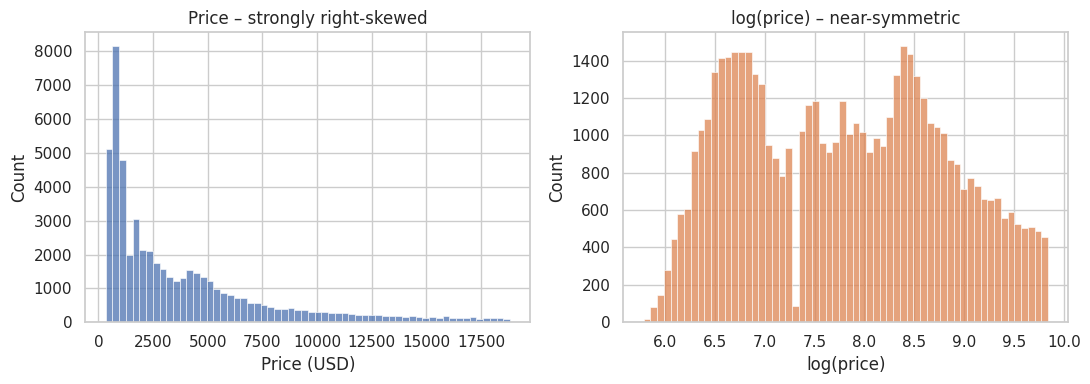

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df.price, bins=60, ax=ax[0]).set(title="Price – strongly right-skewed", xlabel="Price (USD)")
sns.histplot(df.log_price, bins=60, ax=ax[1], color="C1").set(title="log(price) – near-symmetric", xlabel="log(price)")
save("01_hist_price_vs_log")

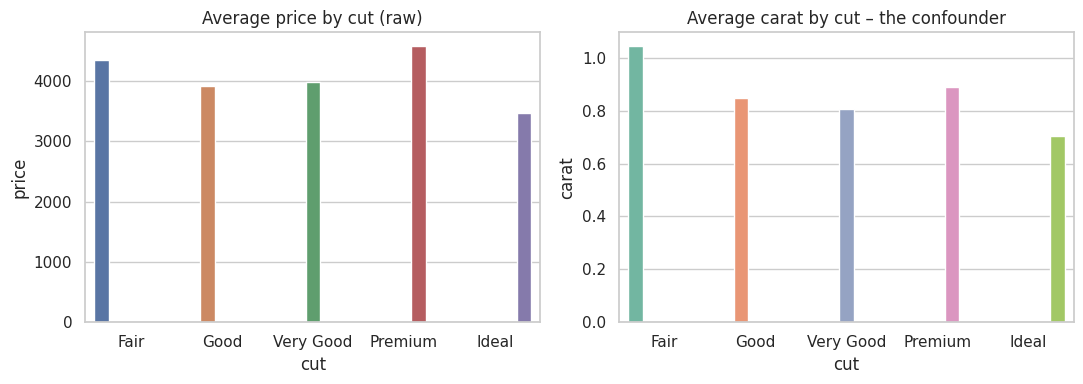

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df, x="cut", y="price", errorbar=None, ax=ax[0], hue="cut", legend=False).set(title="Average price by cut (raw)")
sns.barplot(data=df, x="cut", y="carat", errorbar=None, ax=ax[1], hue="cut", legend=False, palette="Set2").set(title="Average carat by cut – the confounder")
save("02_bar_cut_price_vs_carat")

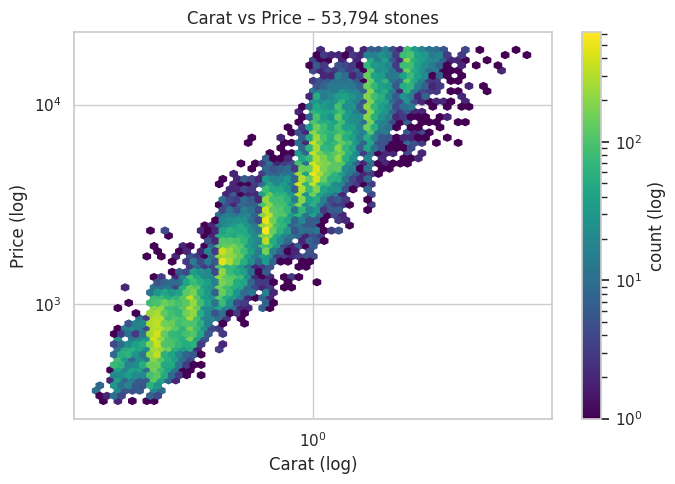

In [28]:
plt.figure(figsize=(7, 5)); plt.hexbin(df.carat, df.price, gridsize=60, bins="log", xscale="log", yscale="log", cmap="viridis")
plt.colorbar(label="count (log)"); plt.xlabel("Carat (log)"); plt.ylabel("Price (log)"); plt.title("Carat vs Price – 53,794 stones")
save("03_hexbin_carat_price")

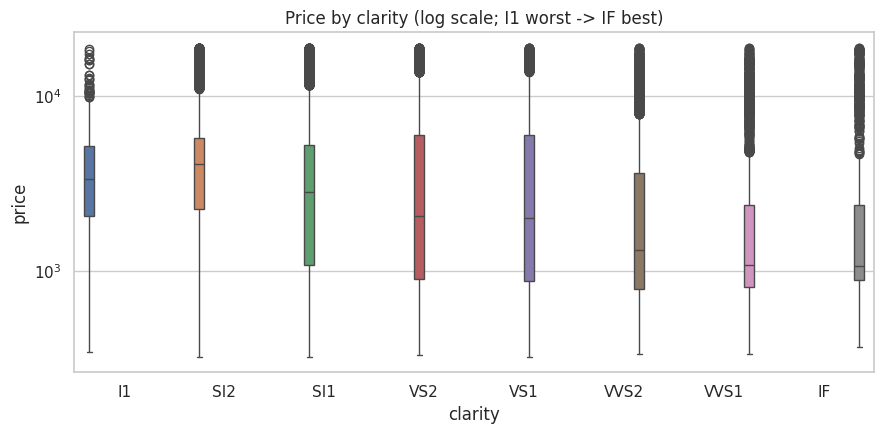

In [29]:
plt.figure(figsize=(9, 4.5)); sns.boxplot(data=df, x="clarity", y="price", hue="clarity", legend=False); plt.yscale("log")
plt.title("Price by clarity (log scale; I1 worst -> IF best)"); save("04_box_clarity_price")

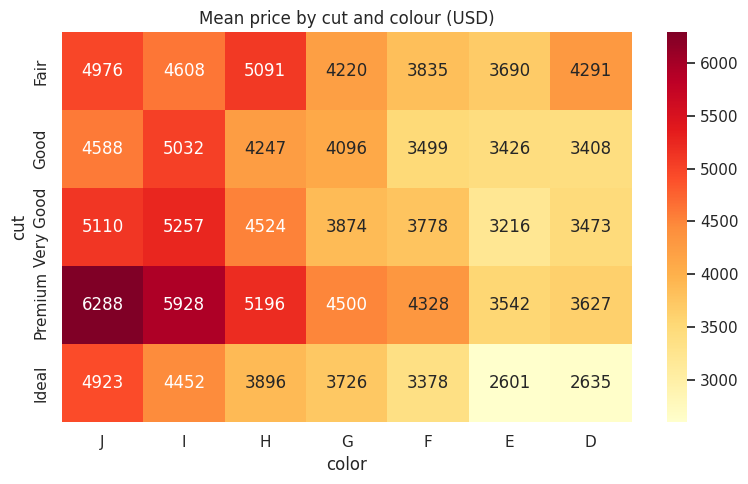

In [30]:
plt.figure(figsize=(8, 5)); sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlOrRd"); plt.title("Mean price by cut and colour (USD)"); save("05_heatmap_cut_color")

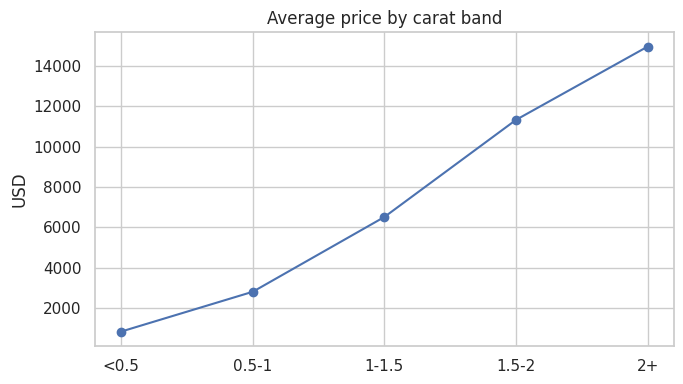

In [31]:
lp = df.groupby("carat_band", observed=True)["price"].mean()
plt.figure(figsize=(7, 4)); plt.plot(lp.index.astype(str), lp.values, marker="o"); plt.title("Average price by carat band"); plt.ylabel("USD"); save("06_line_carat_band")

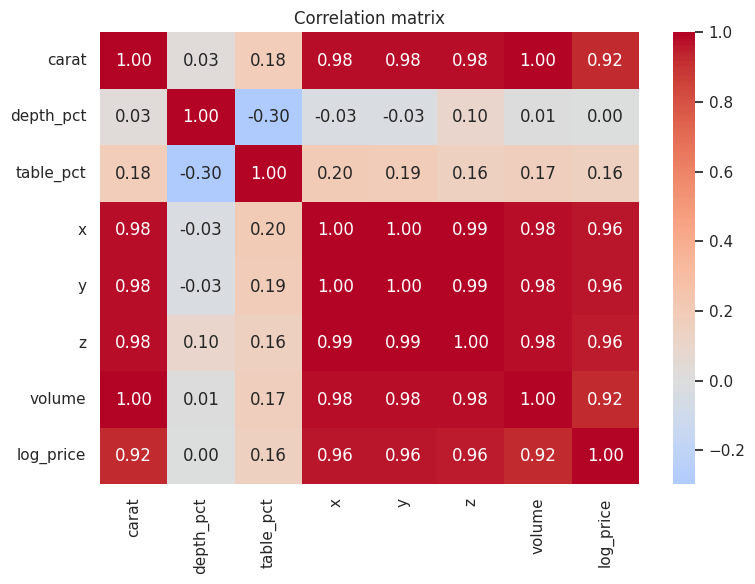

In [32]:
cm = df[["carat", "depth_pct", "table_pct", "x", "y", "z", "volume", "log_price"]].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Correlation matrix"); save("07_heatmap_corr")

## 8. Machine Learning with Scikit-learn

**Plan:** predict `price` from physical and grade features. The target is `log(price)` (see §6.2) and predictions are converted back to dollars for evaluation. A **Pipeline + ColumnTransformer** keeps preprocessing inside cross-validation so there is **no data leakage**. Ordinal categories are encoded with their true order.

In [33]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

cats = ["cut", "color", "clarity"]; nums = ["log_carat", "carat", "depth_pct", "table_pct", "x", "y", "z"]
Xdf = df[cats + nums].copy()
for c in cats: Xdf[c] = Xdf[c].astype(str)
y_log = df["log_price"]; y_usd = df["price"]
Xtr, Xte, ytr, yte, ytr_usd, yte_usd = train_test_split(Xdf, y_log, y_usd, test_size=0.2, random_state=SEED)
print(f"Train {len(Xtr):,} | Test {len(Xte):,}")
order = [["Fair", "Good", "Very Good", "Premium", "Ideal"], list("JIHGFED"), ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]]

def make(model, scale=False):
    pre = ColumnTransformer([("cat", OrdinalEncoder(categories=order), cats),
                             ("num", StandardScaler() if scale else "passthrough", nums)])
    return Pipeline([("prep", pre), ("model", model)])

models = {"Baseline (mean)": make(DummyRegressor()),
          "Linear Regression": make(LinearRegression(), True),
          "Ridge (alpha=1)": make(Ridge(alpha=1.0), True),
          "Random Forest": make(RandomForestRegressor(n_estimators=60, min_samples_leaf=3, n_jobs=-1, random_state=SEED)),
          "Hist Gradient Boosting": make(HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=SEED))}
rows = []; fitted = {}
for name, m in models.items():
    t0 = time.perf_counter(); m.fit(Xtr, ytr); tt = time.perf_counter() - t0
    pred = np.exp(m.predict(Xte)); fitted[name] = m
    rows.append({"model": name, "RMSE_usd": np.sqrt(mean_squared_error(yte_usd, pred)), "MAE_usd": mean_absolute_error(yte_usd, pred),
                 "R2_usd": r2_score(yte_usd, pred), "R2_log": r2_score(yte, np.log(pred)), "train_sec": tt})
res = pd.DataFrame(rows).round(3); print(res.to_string(index=False)); M["models"] = res.to_dict("records")

Train 43,017 | Test 10,755


                 model  RMSE_usd  MAE_usd  R2_usd  R2_log  train_sec
       Baseline (mean)  4214.158 2771.509  -0.143  -0.000      0.025
     Linear Regression   891.618  449.785   0.949   0.979      0.042
       Ridge (alpha=1)   891.817  449.798   0.949   0.979      0.030
         Random Forest   526.687  265.571   0.982   0.992      7.906
Hist Gradient Boosting   525.378  267.974   0.982   0.992      1.174


### 8.1 Cross-validation (5-fold) – is the result stable?

In [34]:
kf = KFold(5, shuffle=True, random_state=SEED); cvres = {}
for name in ["Linear Regression", "Hist Gradient Boosting"]:
    s = cross_val_score(make(models[name].named_steps["model"], name == "Linear Regression"), Xtr, ytr, cv=kf, scoring="r2")
    cvres[name] = (s.mean(), s.std()); print(f"{name:<24} R2(log) per fold = {s.round(4)}  mean = {s.mean():.4f} +/- {s.std():.4f}")
M["cv"] = {k: [f(v[0]), f(v[1])] for k, v in cvres.items()}

Linear Regression        R2(log) per fold = [0.9796 0.9806 0.9803 0.9799 0.9803]  mean = 0.9801 +/- 0.0004


Hist Gradient Boosting   R2(log) per fold = [0.9923 0.9927 0.9926 0.9927 0.9929]  mean = 0.9926 +/- 0.0002


### 8.2 Hyper-parameter tuning with GridSearchCV

In [35]:
small = Xtr.sample(15000, random_state=SEED); ysmall = ytr.loc[small.index]
grid = {"model__learning_rate": [0.05, 0.1], "model__max_depth": [None, 6], "model__max_iter": [200, 400]}
gs = GridSearchCV(make(HistGradientBoostingRegressor(random_state=SEED)), grid, cv=3, scoring="neg_root_mean_squared_error", n_jobs=1).fit(small, ysmall)
print("Best params:", gs.best_params_, "| CV RMSE(log) =", round(-gs.best_score_, 4))
best = make(HistGradientBoostingRegressor(random_state=SEED, **{k.replace("model__", ""): v for k, v in gs.best_params_.items()})).fit(Xtr, ytr)
pb = np.exp(best.predict(Xte))
tuned = dict(RMSE=f(np.sqrt(mean_squared_error(yte_usd, pb))), MAE=f(mean_absolute_error(yte_usd, pb)), R2=f(r2_score(yte_usd, pb)))
print("Tuned model on test set:", tuned); M.update(best_params={k: str(v) for k, v in gs.best_params_.items()}, tuned=tuned)

Best params: {'model__learning_rate': 0.05, 'model__max_depth': None, 'model__max_iter': 400} | CV RMSE(log) = 0.0918


Tuned model on test set: {'RMSE': 528.2303, 'MAE': 268.6067, 'R2': 0.982}


### 8.3 Error analysis and feature importance

In [36]:
pred = np.exp(best.predict(Xte)); resid = yte_usd - pred
band = pd.cut(yte_usd, [0, 1000, 3000, 6000, 10000, 20000], labels=["<1k", "1-3k", "3-6k", "6-10k", "10k+"])
ea = pd.DataFrame({"band": band, "ape": (resid.abs() / yte_usd) * 100}).groupby("band", observed=True)["ape"].agg(["count", "mean"]).round(2)
ea.columns = ["n_test", "MAPE_%"]; print(ea); M["mape_bands"] = ea.reset_index().astype({"band": str}).to_dict("records")
M["mape_overall"] = f((resid.abs() / yte_usd).mean() * 100)
print(f"Overall MAPE: {M['mape_overall']:.2f}% | within 10% of true price: {((resid.abs()/yte_usd) < 0.10).mean():.1%} of test stones")
M["within10"] = f(((resid.abs() / yte_usd) < 0.10).mean() * 100)

idx = Xte.sample(5000, random_state=SEED).index
pi = permutation_importance(best, Xte.loc[idx], yte.loc[idx], n_repeats=5, random_state=SEED, scoring="r2")
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False).round(4); print("\nPermutation importance (drop in R2 when shuffled):"); print(imp)
M["importance"] = imp.to_dict()

       n_test  MAPE_%
band                 
<1k      2931    5.59
1-3k     3089    6.54
3-6k     2472    7.13
6-10k    1279    7.09
10k+      984    6.87
Overall MAPE: 6.51% | within 10% of true price: 79.6% of test stones



Permutation importance (drop in R2 when shuffled):
y            0.4931
log_carat    0.2428
x            0.0879
clarity      0.0833
z            0.0400
color        0.0383
cut          0.0021
depth_pct    0.0007
table_pct    0.0003
carat        0.0000
dtype: float64


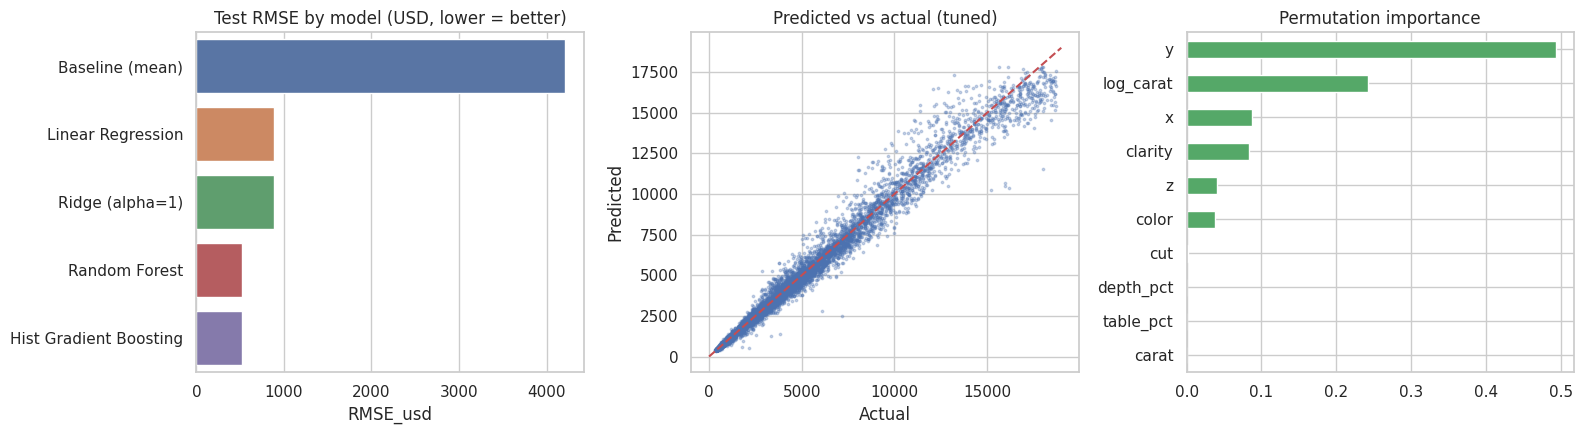

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(data=res, y="model", x="RMSE_usd", ax=ax[0], hue="model", legend=False).set(title="Test RMSE by model (USD, lower = better)", ylabel="")
ax[1].scatter(yte_usd, pred, s=3, alpha=0.3); ax[1].plot([0, 19000], [0, 19000], "r--"); ax[1].set(title="Predicted vs actual (tuned)", xlabel="Actual", ylabel="Predicted")
imp.sort_values().plot.barh(ax=ax[2], color="C2"); ax[2].set_title("Permutation importance")
save("09_model_results")

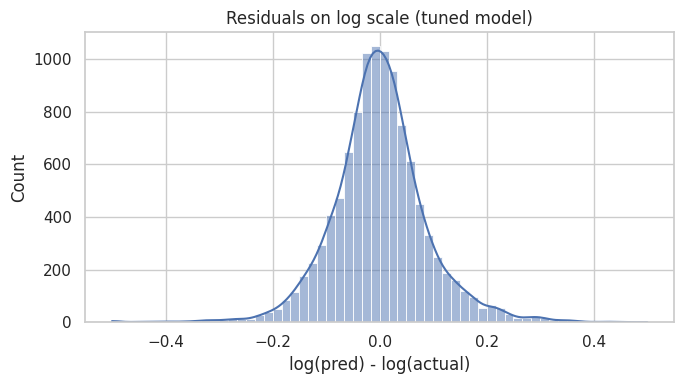

In [38]:
plt.figure(figsize=(7, 4)); sns.histplot((np.log(pred) - yte).clip(-0.5, 0.5), bins=60, kde=True); plt.title("Residuals on log scale (tuned model)"); plt.xlabel("log(pred) - log(actual)")
M["resid_mean"] = f((np.log(pred) - yte).mean()); M["resid_std"] = f((np.log(pred) - yte).std()); save("10_residuals")

## 9. Portfolio Summary – What this project demonstrates
| Skill | Evidence in this notebook |
|---|---|
| Large-data handling | 53,940 rows; vectorised NumPy and Pandas operations |
| Data cleaning | duplicates, impossible values, inconsistent depth, ordered categoricals |
| SQL | aggregation, HAVING, CTE, window functions, results verified against Pandas |
| Statistics | distributions, normality, correlation, CI, bootstrap, t-test, ANOVA, chi-square, Bayes, OLS |
| Machine learning | pipelines, CV, tuning, error analysis, feature importance |
| Communication | 10 charts, interpretation after every result, limitations |

In [39]:
print("KEY RESULTS")
print(f"1. {M['rows_raw']:,} rows -> {M['rows_clean']:,} after removing {dups} duplicates and impossible stones.")
print(f"2. NumPy vectorisation was {M['speedup']:,.0f}x faster than a Python loop on this machine.")
print(f"3. Mean price ${M['p_mean']:,.0f} vs median ${M['p_median']:,.0f}; skew {M['p_skew']:.2f} -> {M['p_skew_log']:.2f} after log transform.")
print(f"4. Price elasticity of carat = {M['ols_elast']:.2f} (a 1% heavier stone costs ~{M['ols_elast']:.2f}% more).")
print(f"5. Raw mean: Ideal ${M['ideal_mean']:,.0f} vs Fair ${M['fair_mean']:,.0f}; Fair stones weigh {M['fair_carat']:.2f} vs {M['ideal_carat']:.2f} carat (confounding).")
print(f"6. Cut explains {M['eta2']:.1%} of log-price variance, carat bands {M['eta2_carat']:.1%}.")
best_name = res.sort_values("RMSE_usd").iloc[0]
print(f"7. Best untuned model: {best_name['model']} (RMSE ${best_name['RMSE_usd']:,.0f}); tuned HGB R2 = {M['tuned']['R2']:.3f}, MAPE {M['mape_overall']:.1f}%.")

KEY RESULTS
1. 53,940 rows -> 53,772 after removing 146 duplicates and impossible stones.
2. NumPy vectorisation was 42x faster than a Python loop on this machine.
3. Mean price $3,931 vs median $2,401; skew 1.62 -> 0.11 after log transform.
4. Price elasticity of carat = 1.88 (a 1% heavier stone costs ~1.88% more).
5. Raw mean: Ideal $3,462 vs Fair $4,341; Fair stones weigh 1.04 vs 0.70 carat (confounding).
6. Cut explains 1.8% of log-price variance, carat bands 87.0%.
7. Best untuned model: Hist Gradient Boosting (RMSE $525); tuned HGB R2 = 0.982, MAPE 6.5%.


### Limitations
- Observational data: relationships are associations, not causal effects.
- Only the stones' own attributes are used; market conditions, certification body and seller are unknown.
- Percentage error is fairly even across price bands (about 5.6% to 7.1% MAPE) but largest for mid-priced stones ($3k-$10k); 20% of test stones are still predicted more than 10% off.
- Permutation importance is shared between correlated features (carat, x, y, z all measure size), so a low score for `carat` does not mean weight is unimportant.

### Recommendations
1. **Pricing:** price on a log scale and by carat band – weight explains most of the variation.
2. **Model use:** use the gradient-boosting pipeline as a pricing *assistant* and manually review stones whose quote differs strongly from the prediction. Tuning on a 15,000-row subsample gave no test gain over the defaults, so the improvement came from the model family (tree ensembles vs linear), not from tuning.
3. **Next steps:** add certification and market-date features, and test quantile regression to give price *ranges*.

In [40]:
json.dump(M, open("data/metrics.json", "w"), indent=1, default=float); print("metrics.json saved with", len(M), "entries")

metrics.json saved with 71 entries
